# FarmTech VisionGuard - FIAP Fase 6

**Aluno:** Pedro Vinicius Gomes dos Santos  
**RM:** 571446  
**Projeto:** visão computacional aplicada a controle de acesso rural.

## Objetivo

Comparar quatro abordagens sobre o mesmo dataset:

1. YOLOv5 customizada - 30 épocas;
2. YOLOv5 customizada - 60 épocas;
3. YOLOv5 padrão pré-treinada em COCO;
4. CNN treinada do zero para classificação.

As classes são `person` e `car`.

> **Integridade acadêmica:** todas as métricas apresentadas neste notebook são geradas
> pela execução real. Não há resultados pré-preenchidos.

# 🚀 EXECUÇÃO SIMPLIFICADA EM UM ÚNICO COLAB

**FarmTech VisionGuard Rural | Pedro Vinicius Gomes dos Santos | RM 571446 | Grupo 60 | FIAP Fase 6**

## O mínimo que você precisa fazer

1. No Google Colab, abra **Ambiente de execução → Alterar tipo de ambiente → GPU T4** (ou outra GPU disponível).
2. Clique em **Ambiente de execução → Executar tudo**. Autorize o Google Drive quando solicitado.
3. O notebook instala os requisitos, monta a pasta no Drive, baixa as **80 imagens**, cria um ZIP com as **64 imagens para o Make Sense**, treina as YOLOs de **30 e 60 épocas**, avalia YOLO padrão, treina CNN e salva as evidências automaticamente.
4. Ao terminar, **salve este notebook com as saídas** em `Meu Drive/FarmTech_VisionGuard/notebooks/PedroGomes_rm571446_pbl_fase6.ipynb` (Arquivo → Salvar uma cópia no Drive / baixar `.ipynb`).
5. Publique o GitHub e vídeo de até 5 minutos; substitua os links no README e gere o PDF final.

### IMPORTANTE: a etapa que não pode ser automatizada legitimamente

O enunciado exige **rotulação feita no Make Sense** para as 64 imagens de treino. Para não bloquear o processamento, o primeiro Run All pode executar em **MODO DEMONSTRAÇÃO com caixas oficiais Open Images**, claramente identificado. **Isso não atende à exigência de Make Sense.** Depois de rotular no Make Sense, coloque os 64 `.txt` do formato YOLO em `Meu Drive/FarmTech_VisionGuard/makesense_export/` ou `makesense_export.zip` e **execute tudo novamente** para treinar com seus rótulos. Se já tiver os rótulos antes da primeira execução, ele usa os rótulos manuais de imediato.

**Não inventamos métricas nem fingimos que a rotulação foi feita.** A nota depende das evidências reais, do GitHub, vídeo e prazo.


In [1]:
# ====== PREPARAÇÃO AUTOMÁTICA: rode com "Executar tudo" ======
from google.colab import drive
from pathlib import Path
import base64,io,zipfile,os,sys,subprocess,shutil

ROOT = Path('/content/drive/MyDrive/FarmTech_VisionGuard')
drive.mount('/content/drive')
ROOT.mkdir(parents=True, exist_ok=True)
print('📁 Drive conectado:', ROOT)

# Pacote de código-fonte incorporado ao próprio notebook: não precisa fazer upload de pastas.
BUNDLE_B64 = (
    "..."
)
with zipfile.ZipFile(io.BytesIO(base64.b64decode(BUNDLE_B64))) as src_zip:
    for item in src_zip.infolist():
        target = (Path('/content/drive/MyDrive')/item.filename).resolve()
        base = Path('/content/drive/MyDrive').resolve()
        if not target.is_relative_to(base):
            raise RuntimeError('Nome de arquivo inseguro no pacote incorporado')
        if item.is_dir():
            target.mkdir(parents=True,exist_ok=True)
            continue
        target.parent.mkdir(parents=True,exist_ok=True)
        if target.name == 'README.md' and target.exists() and 'INSIRA_URL_' not in target.read_text(encoding='utf-8'):
            continue # preservar links do aluno se já preenchidos
        with src_zip.open(item) as original, open(target,'wb') as final:
            shutil.copyfileobj(original, final)
print('✅ Código, scripts e documentação instalados automaticamente no Drive.')

# Um Colab sem GPU fará os treinamentos demorarem demais; detectar logo no início.
import torch
assert torch.cuda.is_available(), ('GPU NÃO ATIVADA! Colab → Ambiente de execução → '
    'Alterar tipo de ambiente → GPU T4 e rode tudo novamente.')
print('✅ GPU detectada:',torch.cuda.get_device_name(0))
subprocess.run([sys.executable,'-m','pip','install','-q',
    'boto3>=1.28','tqdm>=4.65','pandas>=2.0','scikit-learn>=1.3','PyYAML>=6.0',
    'matplotlib>=3.7','nbformat>=5.9','reportlab>=4.0'],check=True)

# Baixar em disco do Colab e copiar apenas arquivos indispensáveis para o Drive.
DATASET = ROOT/'dataset'
manifest = DATASET/'manifest.csv'
ready = manifest.exists() and all(sum(1 for _ in (DATASET/'images'/split).glob('*.jpg')) == count
                                for split,count in [('train',64),('val',8),('test',8)])
if not ready:
    stage=Path('/content/farmtech_stage/dataset')
    print('⬇️ Baixando 80 imagens reais Open Images pela primeira vez...')
    subprocess.run([sys.executable,str(ROOT/'scripts/download_openimages.py'),
        '--output',str(stage),'--seed','42','--workers','8'],check=True)
    DATASET.mkdir(parents=True,exist_ok=True)
    for subdir in ['images','labels','labels_reference']:
        dst=DATASET/subdir
        if dst.exists():shutil.rmtree(dst)
        shutil.copytree(stage/subdir,dst)
    for filename in ['manifest.csv','LABEL_MODE.txt','MAKESENSE_TRAIN_FILES.txt']:
        shutil.copy2(stage/filename,DATASET/filename)
else:
    print('✅ 80 imagens encontradas no Drive: download ignorado.')

# Material conveniente: um ZIP com as 64 fotos de treino para enviar ao Make Sense.
zip_makesense = ROOT/'MAKE_SENSE_64_IMAGENS.zip'
if not zip_makesense.exists():
    with zipfile.ZipFile(zip_makesense,'w',compression=zipfile.ZIP_STORED) as out_zip:
        for photo in sorted((DATASET/'images'/'train').glob('*.jpg')):
            out_zip.write(photo,arcname=photo.name)
print('📦 ZIP para Make Sense:',zip_makesense)

# Se o usuário já tiver exportado as labels do Make Sense, instalar ANTES de treinar.
manual_zip=ROOT/'makesense_export.zip'
manual_folder=ROOT/'makesense_export'
if manual_zip.is_file():
    manual_folder.mkdir(exist_ok=True)
    with zipfile.ZipFile(manual_zip) as archive:
        for member in archive.infolist():
            if member.is_dir() or not member.filename.lower().endswith('.txt'):continue
            # Exportação YOLO: 64 arquivos com nomes correspondentes às imagens.
            if Path(member.filename).name != member.filename:
                print('Nota: pastas internas ignoradas na importação:',member.filename)
            target=manual_folder/Path(member.filename).name
            with archive.open(member) as src, open(target,'wb') as dst: shutil.copyfileobj(src,dst)
if manual_folder.exists() and list(manual_folder.glob('*.txt')):
    if not (DATASET/'LABEL_MODE.txt').read_text(encoding='utf-8').startswith('FINAL_MAKESENSE_TRAIN'):
        print('🔎 Auditando as anotações manuais ...')
        subprocess.run([sys.executable,str(ROOT/'scripts/organize_makesense_labels.py'),
            '--dataset',str(DATASET),'--export-dir',str(manual_folder)],check=True)
    print('✅ Make Sense aplicado e validado.')
else:
    print('⚠️ MODO DEMONSTRAÇÃO: usando caixas oficiais Open Images.')
    print('⚠️ Para a NOTA, é obrigatório rotular as 64 imagens no Make Sense.')

# Validação de integridade antes do custo do treinamento.
sys.path.insert(0,str(ROOT))
from src.dataset_tools import validate_dataset
validation=validate_dataset(DATASET,require_labels=True)
print('Distribuição:',validation.counts)
validation.raise_if_invalid()
print('✅ Preparação automática concluída. Os experimentos começam abaixo.')


Mounted at /content/drive
📁 Drive conectado: /content/drive/MyDrive/FarmTech_VisionGuard
✅ Código, scripts e documentação instalados automaticamente no Drive.
✅ GPU detectada: Tesla T4
✅ 80 imagens encontradas no Drive: download ignorado.
📦 ZIP para Make Sense: /content/drive/MyDrive/FarmTech_VisionGuard/MAKE_SENSE_64_IMAGENS.zip
⚠️ MODO DEMONSTRAÇÃO: usando caixas oficiais Open Images.
⚠️ Para a NOTA, é obrigatório rotular as 64 imagens no Make Sense.
Distribuição: {'train': {'person': 32, 'car': 32}, 'val': {'person': 4, 'car': 4}, 'test': {'person': 4, 'car': 4}}
✅ Preparação automática concluída. Os experimentos começam abaixo.


### Guia de leitura: como acompanhar este notebook

**Autor:** Pedro Vinicius Gomes dos Santos | **RM:** 571446 | **Grupo:** 60.

Este caderno contém as duas entregas obrigatórias da FIAP em sequência. Você não precisa conhecer os comandos previamente, mas deve ler cada descrição antes de executar.

**Fluxo:** 80 imagens reais → treino/validação/teste → rotulação manual Make Sense → YOLO 30 épocas → YOLO 60 épocas → YOLO padrão → CNN do zero → métricas → prints → análise crítica.

**Integridade:** imagens, pesos e métricas *não estão preenchidos previamente*. Resultados aparecem somente após execução real no Colab. Se uma etapa falhar, interrompa, investigue e não use números artificiais para substituir a saída.

**Observação acadêmica:** o aplicativo rural em Streamlit é uma aplicação complementar. Sua YOLO11n pré-treinada não substitui nenhum dos experimentos deste notebook.


## 1. Preparação do ambiente

Ative GPU no Colab em **Ambiente de execução > Alterar tipo de ambiente > GPU**.
O projeto usa seed 42 para favorecer reprodutibilidade.

In [2]:
import os, sys, json, time, shutil, random, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Retrocompatibilidade para checkpoints legados YOLOv5 v7.0 com PyTorch >= 2.6.
# Aplique SOMENTE a pesos confiáveis gerados no Colab / repositório oficial.
os.environ['TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD'] = '1'

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
    print("Python:", sys.version.split()[0])
    print("PyTorch:", torch.__version__)
except Exception as e:
    print("PyTorch será configurado adiante:", e)

GPU: Tesla T4
Python: 3.13.15
PyTorch: 2.11.0+cu130


### Por que precisamos de GPU, seed e versões controladas?

**GPU:** acelera multiplicações de matrizes e treinamento de redes neurais; disponibilidade e potência variam entre sessões gratuitas do Colab. **Seed 42:** controla parte da aleatoriedade para tornar a comparação mais justa, mas não garante resultados bit a bit idênticos em todas as GPUs. **Versões:** uma biblioteca atualizada pode mudar saídas e quebrar um treinamento reproduzível.

**Conferência esperada:** a célula anterior deve ter mostrado o hardware. Se não houver GPU, o treinamento pode demorar muito. Não declare um tempo de treinamento comparável sem registrar essas condições.


## 2. Conectar ao Google Drive e localizar o projeto

A pasta esperada é:

`MyDrive/FarmTech_VisionGuard/`

Ela deve conter `dataset/`, `src/` e os demais arquivos deste repositório.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE_ROOT = Path('/content/drive/MyDrive/FarmTech_VisionGuard')
DATASET_DRIVE = DRIVE_ROOT / 'dataset'
LOCAL_DATASET = Path('/content/farmtech_dataset')
RESULTS = DRIVE_ROOT / 'results'
RESULTS.mkdir(parents=True, exist_ok=True)

assert DRIVE_ROOT.exists(), f"Copie o projeto para {DRIVE_ROOT}"
sys.path.insert(0, str(DRIVE_ROOT))
print("Projeto:", DRIVE_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Projeto: /content/drive/MyDrive/FarmTech_VisionGuard


### Por que exatamente 80 imagens e como evitar vazamento de dados?

O enunciado exige 40 fotos da classe `person` e 40 fotos da classe `car`. Para cada classe, separe **32 treino, 4 validação e 4 teste**. Treino ajusta pesos; validação orienta escolhas e acompanha generalização; teste deve ser usado somente para estimar desempenho final.

**Risco metodológico:** fotografias duplicadas, ângulos quase idênticos ou imagens de teste reutilizadas para ajustar o modelo elevam artificialmente as métricas. Antes de treinar, inspecione imagens, IDs e coerência dos splits.


## 3. Aquisição do dataset - executar somente se as 80 imagens ainda não existirem

O script baixa **fotografias reais** do Open Images V7. As bounding boxes originais do
Open Images **não são usadas como substituto da atividade de rotulação**.

Se o dataset já está pronto e rotulado no Drive, pule esta célula.

In [4]:
# O dataset deve ser preparado antes deste notebook.
# O dataset é preparado automaticamente pelas células iniciais deste caderno. Não é necessário abrir outro notebook.
assert DATASET_DRIVE.exists(), "A preparação automática não concluiu. Confira o erro no início deste notebook."
print("✅ Dataset localizado:", DATASET_DRIVE)

✅ Dataset localizado: /content/drive/MyDrive/FarmTech_VisionGuard/dataset


### Distinguir uma referência pública de uma anotação feita por você

As caixas oficiais do Open Images permitem testar o processo e auditar a qualidade do dataset. Entretanto, o professor exige rotulação das imagens de **treinamento** no Make Sense: 64 fotografias, classes `person` e `car`, exportação YOLO.

No arquivo YOLO, uma linha representa um objeto: `classe centro_x centro_y largura altura`, com valores normalizados. Classe 0 = pessoa; classe 1 = carro. Uma imagem pode conter mais de uma anotação; não aceite caixas trocadas ou incompletas.


## 4. Rotulação manual no Make Sense - etapa obrigatória do enunciado

Use `docs/ROTULAGEM_MAKESENSE.md`.

As **64 imagens de treinamento** devem ser rotuladas no Make Sense, embora o enunciado destaque
as imagens de treinamento. Isso permite medir os modelos também no conjunto de teste.

Classes e índices:

- `0 = person`
- `1 = car`

Após exportar do Make Sense, organize as labels com o script fornecido.

### O que a validação automática consegue verificar?

O programa pode contar imagens, conferir se faltam arquivos, verificar formatos, coordenadas entre 0 e 1 e relação do manifesto com os rótulos. Ele **não comprova** que toda caixa delimita corretamente o objeto. Por isso há inspeção visual e auditoria Make Sense em etapas separadas.


## 5. Validação automática do dataset

Esta célula impede o treinamento se a estrutura não possuir exatamente:

- treino: 32 `person` + 32 `car`;
- validação: 4 + 4;
- teste: 4 + 4;
- labels YOLO válidas para todas as imagens.

In [5]:
from src.dataset_tools import validate_dataset

report = validate_dataset(DATASET_DRIVE, require_labels=True)
print("Contagens:", report.counts)
print("Labels:", report.label_files)
report.raise_if_invalid()
print("✅ Dataset validado com sucesso.")

Contagens: {'train': {'person': 32, 'car': 32}, 'val': {'person': 4, 'car': 4}, 'test': {'person': 4, 'car': 4}}
Labels: {'train': 64, 'val': 8, 'test': 8}
✅ Dataset validado com sucesso.



### Origem das labels

O pipeline pode rodar em dois modos:

- `DEMO_OPENIMAGES_OFFICIAL`: totalmente funcional para validar código e treinamento.
- `FINAL_MAKESENSE_TRAIN`: versão de entrega, com treino rotulado no Make Sense.

**Para entrega à FIAP, o segundo modo é o esperado.**


In [6]:

label_mode = (DATASET_DRIVE/'LABEL_MODE.txt').read_text(encoding='utf-8').strip()
print(label_mode)
if label_mode.startswith('DEMO_'):
    print('⚠️ MODO DEMO: execute o Make Sense antes da entrega final.')
else:
    print('✅ Labels de treino provenientes do Make Sense.')


DEMO_OPENIMAGES_OFFICIAL
Antes da entrega final, substitua labels/train pelas labels do Make Sense.
⚠️ MODO DEMO: execute o Make Sense antes da entrega final.


## 6. Copiar o dataset para o armazenamento local do Colab

Treinar diretamente pelo Google Drive pode aumentar a latência de I/O. Por isso,
mantemos a fonte de verdade no Drive e usamos uma cópia local durante o treinamento.

In [7]:
if LOCAL_DATASET.exists():
    shutil.rmtree(LOCAL_DATASET)
shutil.copytree(DATASET_DRIVE, LOCAL_DATASET)
print("Cópia local:", LOCAL_DATASET)

Cópia local: /content/farmtech_dataset


### Leitura visual das boxes

A bounding box é o retângulo que delimita o objeto detectado. A imagem pode conter pessoas ao fundo ou carros parcialmente ocluídos; rotulações incompletas geram erros de avaliação. Observe se a caixa envolve o objeto real, se há rótulos das duas classes e se o contraste/iluminação tornam a tarefa difícil.

**Para registrar no relatório:** selecione exemplos representativos e descreva a dificuldade visual sem afirmar que o modelo já aprendeu algo nesta etapa.


## 7. Inspeção visual do dataset e das bounding boxes

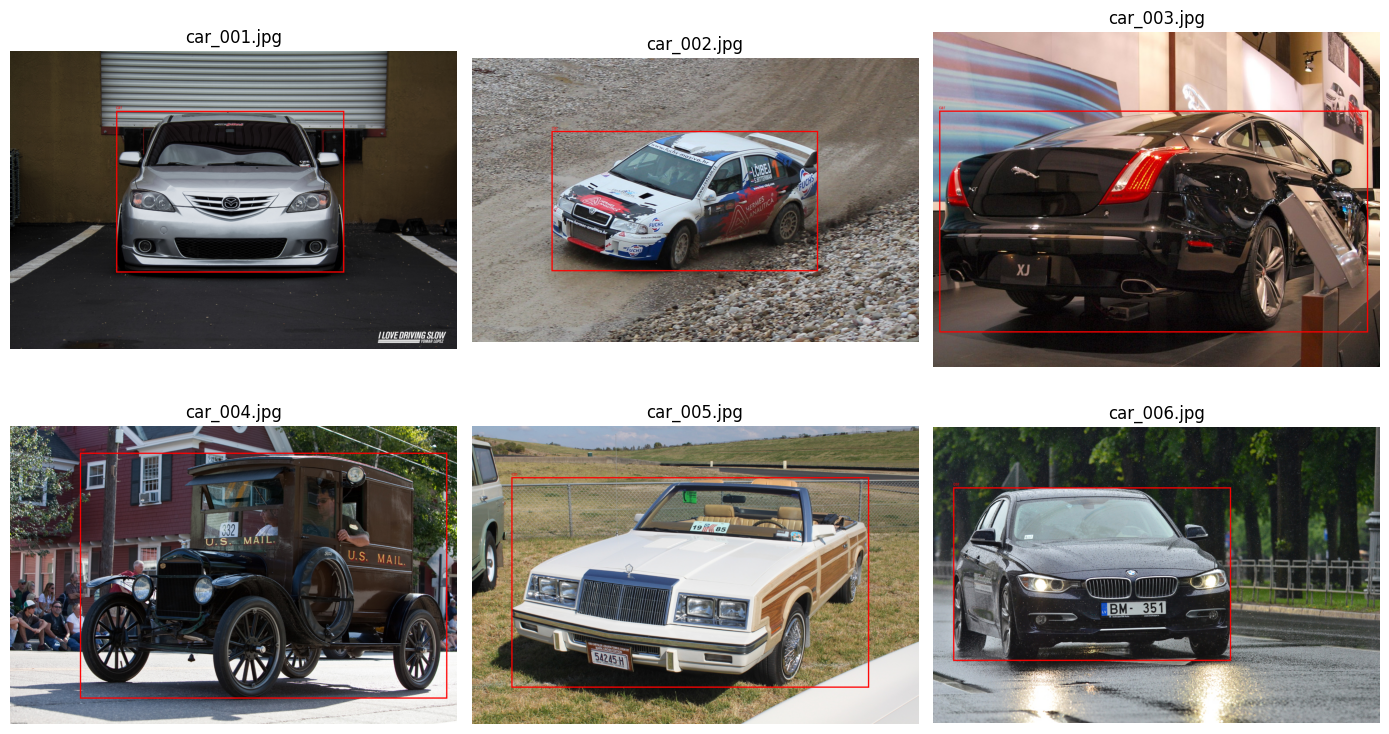

In [8]:
from PIL import Image, ImageDraw

def show_examples(dataset_root, split='train', n=6):
    image_dir = Path(dataset_root) / 'images' / split
    label_dir = Path(dataset_root) / 'labels' / split
    paths = sorted([p for p in image_dir.iterdir() if p.suffix.lower() in {'.jpg','.jpeg','.png'}])[:n]
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    axes = axes.ravel()
    for ax, path in zip(axes, paths):
        img = Image.open(path).convert('RGB')
        draw = ImageDraw.Draw(img)
        w, h = img.size
        label_path = label_dir / f'{path.stem}.txt'
        for line in label_path.read_text().splitlines():
            cls, x, y, bw, bh = map(float, line.split())
            x1=(x-bw/2)*w; y1=(y-bh/2)*h; x2=(x+bw/2)*w; y2=(y+bh/2)*h
            draw.rectangle((x1,y1,x2,y2), outline='red', width=max(2, w//300))
            draw.text((x1, max(0,y1-14)), 'person' if int(cls)==0 else 'car', fill='red')
        ax.imshow(img)
        ax.set_title(path.name)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

show_examples(LOCAL_DATASET)

## 8. Instalar YOLOv5

A atividade menciona YOLOv5 e diretórios `yolov5/runs/...`, então fixamos a versão
estável `v7.0` para reprodutibilidade.

Compatibilidade: aplicamos uma correção localizada no checkout YOLOv5 para fontes Pillow modernas. Checkpoints PyTorch legados são carregados apenas quando provêm de fonte confiável; não carregue arquivos `.pt` de terceiros.

In [9]:
%cd /content
import shutil, subprocess
from pathlib import Path

if Path('/content/yolov5').exists():
    shutil.rmtree('/content/yolov5')

subprocess.run(["git", "clone", "-q", "--branch", "v7.0", "--depth", "1", "https://github.com/ultralytics/yolov5.git", "/content/yolov5"], check=True)
%cd /content/yolov5
!pip -q install -r requirements.txt
# Ajusta apenas o checkout YOLOv5 e mantém Pillow instalado.
!python "{DRIVE_ROOT}/scripts/ajustar_yolov5_v7.py" --repo /content/yolov5

YOLOV5_COMMIT = subprocess.check_output(
    ['git','-C','/content/yolov5','rev-parse','HEAD'],
    text=True
).strip()
print('YOLOv5 commit:', YOLOV5_COMMIT)

dataset_yaml = Path('/content/farmtech.yaml')
dataset_yaml.write_text(f'''path: {LOCAL_DATASET}
train: images/train
val: images/val
test: images/test
names:
  0: person
  1: car
''')
print(dataset_yaml.read_text())

/content
/content/yolov5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.5/228.5 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.8/62.8 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 100.4 MB/s eta 0:00:00
Patch Pillow para checkout YOLOv5: aplicado
YOLOv5 commit: 915bbf294bb74c859f0b41f1c23bc395014ea679
path: /content/farmtech_dataset
train: images/train
val: images/val
test: images/test
names:
  0: person
  1: car



### Hipótese experimental H1: aumentar épocas melhora o detector?

A época corresponde a uma passagem completa pelo conjunto de treinamento. Mais épocas podem permitir aprendizado adicional, mas também aumentar custo e **overfitting** (quando o modelo memoriza padrões do treino e perde generalização).

Compare, sob condições equivalentes, as curvas de treino/validação, mAP50 e Precision/Recall, além dos segundos gastos. **Não conclua que 60 é melhor apenas por ser maior.**


# Entrega 1 - YOLO customizada

## 9. Experimento A - 30 épocas

Configuração mantida fixa:
- YOLOv5s;
- imagem 512;
- batch 16;
- seed 42;
- pesos `yolov5s.pt`.

A única variável que será alterada no experimento seguinte é a quantidade de épocas.

In [10]:
%cd /content/yolov5
import subprocess
start = time.perf_counter()
cmd = [sys.executable, "train.py", "--img", "512", "--batch", "16", "--epochs", "30",
       "--data", "/content/farmtech.yaml", "--weights", "yolov5s.pt",
       "--project", "/content/farmtech_runs", "--name", "yolo_30_epochs",
       "--seed", "42", "--cache", "ram", "--exist-ok"]
subprocess.run(cmd, check=True)
TRAIN30_SECONDS = time.perf_counter() - start
weights_path = Path("/content/farmtech_runs/yolo_30_epochs/weights/best.pt")
assert weights_path.is_file(), f"Treinamento 30 não gerou checkpoint"
print(f"Treinamento 30: {TRAIN30_SECONDS:.1f} segundos")

/content/yolov5
Treinamento 30: 89.0 segundos


### Como avaliar sem esconder falhas

Uma detecção é considerada correta quando classe e localização coincidem suficientemente com o ground truth, usando o limiar de IoU escolhido. Falsos positivos são caixas sem objeto correspondente; falsos negativos são objetos existentes que passaram despercebidos.

As métricas do conjunto de teste devem aparecer com contexto: somente **oito imagens** participam do teste, portanto qualquer conclusão tem elevada incerteza.


### Avaliação no conjunto de teste - 30 épocas

In [11]:
%cd /content
sys.path.insert(0, str(DRIVE_ROOT))
from src.detection_eval import evaluate_torchhub_model, save_metrics

model30 = torch.hub.load('/content/yolov5', 'custom',
                         path='/content/farmtech_runs/yolo_30_epochs/weights/best.pt',
                         source='local')
metrics30 = evaluate_torchhub_model(model30, LOCAL_DATASET, split='test', class_map={0:0,1:1})
payload30 = metrics30.to_dict()
payload30['training_seconds'] = TRAIN30_SECONDS
save_metrics(payload30, RESULTS/'yolo_custom_30_metrics.json')
payload30

/content


/content/yolov5/utils/general.py:34: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as pkg
YOLOv5 🚀 v7.0-0-g915bbf2 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 157 layers, 7015519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
/content/yolov5/models/common.py:702: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast(autocast):
/content/yolov5/models/common.py:702: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast(autocast):
/content/yolov5/models/common.py:702: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Pleas

{'precision': 0.0031446540880503146,
 'recall': 1.0,
 'f1': 0.006269592476489028,
 'map50': 0.7625,
 'ap50_person': 0.5249999999999999,
 'ap50_car': 1.0,
 'mean_inference_ms': 86.47860912499539,
 'num_images': 8,
 'training_seconds': 88.99643592199999}

## 10. Experimento B - 60 épocas

Mesmos dados e hiperparâmetros. O objetivo é observar se dobrar as épocas melhora a
generalização ou apenas aumenta custo/overfitting.

In [12]:
%cd /content/yolov5
import subprocess
start = time.perf_counter()
cmd = [sys.executable, "train.py", "--img", "512", "--batch", "16", "--epochs", "60",
       "--data", "/content/farmtech.yaml", "--weights", "yolov5s.pt",
       "--project", "/content/farmtech_runs", "--name", "yolo_60_epochs",
       "--seed", "42", "--cache", "ram", "--exist-ok"]
subprocess.run(cmd, check=True)
TRAIN60_SECONDS = time.perf_counter() - start
weights_path = Path("/content/farmtech_runs/yolo_60_epochs/weights/best.pt")
assert weights_path.is_file(), f"Treinamento 60 não gerou checkpoint"
print(f"Treinamento 60: {TRAIN60_SECONDS:.1f} segundos")

/content/yolov5
Treinamento 60: 104.5 segundos


### Avaliação no conjunto de teste - 60 épocas

In [13]:
%cd /content
model60 = torch.hub.load('/content/yolov5', 'custom',
                         path='/content/farmtech_runs/yolo_60_epochs/weights/best.pt',
                         source='local')
metrics60 = evaluate_torchhub_model(model60, LOCAL_DATASET, split='test', class_map={0:0,1:1})
payload60 = metrics60.to_dict()
payload60['training_seconds'] = TRAIN60_SECONDS
save_metrics(payload60, RESULTS/'yolo_custom_60_metrics.json')
payload60

YOLOv5 🚀 v7.0-0-g915bbf2 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 157 layers, 7015519 parameters, 0 gradients, 15.8 GFLOPs


/content


Adding AutoShape... 
/content/yolov5/models/common.py:702: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast(autocast):
/content/yolov5/models/common.py:702: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast(autocast):
/content/yolov5/models/common.py:702: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast(autocast):
/content/yolov5/models/common.py:702: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast(autocast):
/content/yolov5/models/common.py:702: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast(autocast):
/content/yolov5/mod

{'precision': 0.02247191011235955,
 'recall': 1.0,
 'f1': 0.04395604395604395,
 'map50': 0.8958333333333333,
 'ap50_person': 0.7916666666666666,
 'ap50_car': 1.0,
 'mean_inference_ms': 26.85777237500986,
 'num_images': 8,
 'training_seconds': 104.45986093299996}

### Interpretação das curvas

Se a perda de treino cair enquanto a validação piorar, pode haver sobreajuste. Se ambas melhorarem, o treinamento adicional pode ter ajudado. Se as curvas oscilarem, o tamanho reduzido do dataset e a aleatoriedade são explicações plausíveis.

**Evidências recomendadas:** mostre pelo menos um gráfico de perda e um gráfico de desempenho por treino; comente o que ocorreu **com seus resultados reais**.


## 11. Curvas dos treinamentos YOLO

In [14]:
r30 = pd.read_csv('/content/farmtech_runs/yolo_30_epochs/results.csv')
r60 = pd.read_csv('/content/farmtech_runs/yolo_60_epochs/results.csv')

# YOLOv5 formata os cabeçalhos do CSV com alinhamento; strip evita KeyError
r30.columns = [col.strip() for col in r30.columns]
r60.columns = [col.strip() for col in r60.columns]

def compare_curve(column, ylabel, title):
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(r30.index + 1, r30[column], label='30 épocas')
    ax.plot(r60.index + 1, r60[column], label='60 épocas')
    ax.set_xlabel('Época')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=.2)
    plt.show()

compare_curve('metrics/mAP_0.5', 'mAP@0.5', 'mAP@0.5 de validação')
compare_curve('train/box_loss', 'Box loss', 'Erro de localização - treino')
compare_curve('train/obj_loss', 'Objectness loss', 'Erro de objectness - treino')
compare_curve('train/cls_loss', 'Classification loss', 'Erro de classificação - treino')

summary_epochs = pd.DataFrame([
    {
        'experimento': 'YOLO custom 30',
        'melhor_mAP50_val': float(r30['metrics/mAP_0.5'].max()),
        'menor_box_loss_val': float(r30['val/box_loss'].min()),
        'tempo_treino_s': TRAIN30_SECONDS,
    },
    {
        'experimento': 'YOLO custom 60',
        'melhor_mAP50_val': float(r60['metrics/mAP_0.5'].max()),
        'menor_box_loss_val': float(r60['val/box_loss'].min()),
        'tempo_treino_s': TRAIN60_SECONDS,
    },
])
summary_epochs

,experimento,melhor_mAP50_val,menor_box_loss_val,tempo_treino_s
0,YOLO custom 30,0.995,0.024358,88.996436
1,YOLO custom 60,0.995,0.017843,104.459861


### Hipótese experimental H2: o modelo público generaliza para nossa amostra?

A YOLOv5 padrão utiliza pesos pré-treinados em COCO. Como COCO contém `person` e `car`, ela pode detectar ambas sem ajuste para o novo conjunto. A YOLOv5 customizada é adaptada às imagens de treino do projeto.

A comparação deve manter resolução, convenções e critérios de avaliação comparáveis. Não use o desempenho de YOLO11n no aplicativo como se fosse o benchmark YOLOv5 deste notebook.


# Entrega 2 - comparação com abordagens concorrentes

## 12. YOLOv5 padrão - sem customização

A YOLOv5 padrão usa classes COCO. Nesta avaliação, somente:

- COCO `person=0` -> projeto `person=0`;
- COCO `car=2` -> projeto `car=1`.

A avaliação usa as mesmas imagens e ground truth do teste, com IoU 0.50.

In [15]:
%cd /content
standard = torch.hub.load('/content/yolov5', 'yolov5s', source='local', pretrained=True)
metrics_std = evaluate_torchhub_model(
    standard, LOCAL_DATASET, split='test', class_map={0:0, 2:1}
)
payload_std = metrics_std.to_dict()
payload_std['training_seconds'] = 0.0
save_metrics(payload_std, RESULTS/'yolo_standard_metrics.json')
payload_std

YOLOv5 🚀 v7.0-0-g915bbf2 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)



/content


100%|██████████| 14.1M/14.1M [00:00<00:00, 158MB/s]

Fusing layers... 
YOLOv5s summary: 213 layers, 7225885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 
/content/yolov5/models/common.py:702: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast(autocast):
/content/yolov5/models/common.py:702: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast(autocast):
/content/yolov5/models/common.py:702: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast(autocast):
/content/yolov5/models/common.py:702: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast(autocast):
/content/yolov5/models/common.py:702: FutureWarning: `torch.cuda.a

{'precision': 0.05228758169934641,
 'recall': 1.0,
 'f1': 0.09937888198757763,
 'map50': 0.875,
 'ap50_person': 0.75,
 'ap50_car': 1.0,
 'mean_inference_ms': 23.95983362499976,
 'num_images': 8,
 'training_seconds': 0.0}

### Detecção x classificação: duas tarefas diferentes

A YOLO recebe uma imagem e devolve **várias** predições localizadas (classe e caixa). A CNN deste exercício recebe uma imagem e prevê **uma classe principal**. Ela não produz bounding boxes.

Por isso **mAP50 não pode ser comparado diretamente com Accuracy**. Um modelo pode classificar corretamente uma imagem e ainda ser incapaz de dizer onde está o objeto.


## 13. CNN treinada do zero

Diferentemente da YOLO, a CNN responde a uma tarefa de **classificação**: ela decide se
a imagem pertence à classe `person` ou `car`, sem produzir bounding boxes.

Essa diferença será explicitada na conclusão; mAP de detecção não será confundido com
accuracy de classificação.

In [16]:
%cd /content

# Libera memória dos detectores antes da CNN
for _name in ['model30', 'model60', 'standard']:
    if _name in globals():
        del globals()[_name]
if torch.cuda.is_available():
    torch.cuda.empty_cache()

import tensorflow as tf
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from src.cnn_tools import build_cnn, make_tf_dataset, paths_and_labels, measure_keras_inference

train_paths, train_labels = paths_and_labels(LOCAL_DATASET, 'train')
val_paths, val_labels = paths_and_labels(LOCAL_DATASET, 'val')
test_paths, test_labels = paths_and_labels(LOCAL_DATASET, 'test')

train_ds = make_tf_dataset(train_paths, train_labels, training=True)
val_ds = make_tf_dataset(val_paths, val_labels)
test_ds = make_tf_dataset(test_paths, test_labels)

cnn = build_cnn()
cnn.summary()

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', patience=3, factor=0.5, min_lr=1e-6),
]

start = time.perf_counter()
history = cnn.fit(train_ds, validation_data=val_ds, epochs=35, callbacks=callbacks, verbose=1)
CNN_TRAIN_SECONDS = time.perf_counter() - start

/content


Model: "farmtech_cnn_from_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 192)    │       221,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 192)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 192)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 327,041 (1.25 MB)

 Trainable params: 327,041 (1.25 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/35
8/8 ━━━━━━━━━━━━━━━━━━━━ 6s 89ms/step - accuracy: 0.4688 - loss: 0.7042 - precision: 0.4583 - recall: 0.3438 - val_accuracy: 0.5000 - val_loss: 0.6989 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/35
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.5312 - loss: 0.6988 - precision: 0.5714 - recall: 0.2500 - val_accuracy: 0.5000 - val_loss: 0.6946 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 3/35
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.5156 - loss: 0.6765 - precision: 0.5333 - recall: 0.2500 - val_accuracy: 0.5000 - val_loss: 0.6989 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 4/35
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.5469 - loss: 0.6795 - precision: 0.6667 - recall: 0.1875 - val_accuracy: 0.3750 - val_loss: 0.7145 - val_precision: 0.3333 - val_recall: 0.2500 - learning_rate: 0.0010
Epoch 5/35
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - a

### Como ler a matriz de confusão da CNN

Para classificação binária, a matriz compara rótulo real e previsão. A diagonal corresponde aos acertos; posições fora da diagonal correspondem a trocas entre `person` e `car`. Não confunda a quantidade de imagens avaliadas com a quantidade de caixas existentes nas fotos.


### Avaliação da CNN no teste

In [17]:
probs = cnn.predict(test_ds, verbose=0).ravel()
pred = (probs >= 0.5).astype(int)
truth = np.array(test_labels)

acc = accuracy_score(truth, pred)
precision, recall, f1, _ = precision_recall_fscore_support(
    truth, pred, average='binary', zero_division=0
)
macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
    truth, pred, average='macro', zero_division=0
)
mean_ms = measure_keras_inference(cnn, test_ds)

cnn_metrics = {
    'accuracy': float(acc),
    'precision': float(precision),
    'recall': float(recall),
    'f1': float(f1),
    'macro_precision': float(macro_precision),
    'macro_recall': float(macro_recall),
    'macro_f1': float(macro_f1),
    'mean_inference_ms': float(mean_ms),
    'training_seconds': float(CNN_TRAIN_SECONDS),
    'num_images': int(len(truth)),
}
(RESULTS/'cnn_metrics.json').write_text(json.dumps(cnn_metrics, indent=2))
cnn_metrics

cnn.save(RESULTS/'cnn_from_scratch.keras')
print('Modelo CNN salvo no Drive.')

Modelo CNN salvo no Drive.


In [18]:
cm = confusion_matrix(truth, pred, labels=[0,1])
disp = ConfusionMatrixDisplay(cm, display_labels=['person','car'])
disp.plot(values_format='d')
plt.title('CNN - matriz de confusão no teste')
plt.show()

fig, ax = plt.subplots(figsize=(10,5))
ax.plot(history.history['accuracy'], label='treino')
ax.plot(history.history['val_accuracy'], label='validação')
ax.set_xlabel('Época')
ax.set_ylabel('Accuracy')
ax.set_title('CNN - accuracy')
ax.legend()
ax.grid(alpha=.2)
plt.show()

### Critérios de comparação exigidos no enunciado

**Precisão e erros:** use métricas válidas para cada tarefa. **Treinamento:** informe tempo e custo computacional, quando aplicável. **Inferência:** meça latência em condições documentadas. **Integração:** compare facilidade de carregar pesos, instalar bibliotecas, pré-processar dados e implantar em um computador de fazenda.

Informe configurações e não transforme diferenças de hardware, resolução ou tarefa em afirmações de superioridade científica.


# 14. Comparação consolidada

A tabela abaixo usa **resultados efetivamente medidos nesta execução**.

In [19]:
from src.reporting import save_comparison

comparison = save_comparison(RESULTS)
comparison

,modelo,tipo,accuracy,precision,recall,...,map50,ap50_person,ap50_car,mean_inference_ms,training_seconds
0,YOLOv5 custom - 30 épocas,detecção,NaN,0.003145,1.0,...,0.762500,0.525000,1.0,86.478609,88.996436
1,YOLOv5 custom - 60 épocas,detecção,NaN,0.022472,1.0,...,0.895833,0.791667,1.0,26.857772,104.459861
2,YOLOv5 padrão COCO,detecção,NaN,0.052288,1.0,...,0.875000,0.750000,1.0,23.959834,0.000000
3,CNN do zero,classificação,0.5,0.000000,0.0,...,NaN,NaN,NaN,20.433497,9.979911


## 14.1 Comparação de facilidade de uso e integração

Além das métricas numéricas, o enunciado pede uma avaliação crítica sobre integração,
customização e custo operacional. A tabela abaixo explicita essas diferenças.

- **YOLOv5 padrão:** integração mais rápida, pois não exige novo treinamento.
- **YOLOv5 customizada:** exige rotulação e treinamento, mas adapta o detector ao domínio.
- **CNN do zero:** arquitetura simples para classificação, porém não localiza objetos.

In [20]:
qualitative = pd.DataFrame([
    {
        'abordagem': 'YOLOv5 padrão',
        'facilidade_integracao': 'Alta',
        'precisa_rotulacao_custom': 'Não',
        'precisa_treinamento': 'Não',
        'localiza_objetos': 'Sim',
        'principal_tradeoff': 'Rápida de integrar, mas sem adaptação ao domínio'
    },
    {
        'abordagem': 'YOLOv5 customizada',
        'facilidade_integracao': 'Média',
        'precisa_rotulacao_custom': 'Sim',
        'precisa_treinamento': 'Sim',
        'localiza_objetos': 'Sim',
        'principal_tradeoff': 'Maior trabalho, porém especializada nas duas classes'
    },
    {
        'abordagem': 'CNN do zero',
        'facilidade_integracao': 'Média',
        'precisa_rotulacao_custom': 'Classe por imagem',
        'precisa_treinamento': 'Sim',
        'localiza_objetos': 'Não',
        'principal_tradeoff': 'Classifica bem o cenário, mas não retorna bounding boxes'
    },
])
qualitative

,abordagem,facilidade_integracao,precisa_rotulacao_custom,precisa_treinamento,localiza_objetos,principal_tradeoff
0,YOLOv5 padrão,Alta,Não,Não,Sim,"Rápida de integrar, mas sem adaptação ao domínio"
1,YOLOv5 customizada,Média,Sim,Sim,Sim,"Maior trabalho, porém especializada nas duas c..."
2,CNN do zero,Média,Classe por imagem,Sim,Não,"Classifica bem o cenário, mas não retorna boun..."


### Checklist de uma conclusão realmente crítica

1. Qual modelo apresentou melhor resultado em **seu experimento** e com qual métrica?
2. O aumento de épocas compensou o custo? Há sinais de overfitting?
3. Quais foram os erros mais importantes e quais imagens ilustram isso?
4. O dataset de apenas oito imagens de teste permite generalizar para todas as fazendas? **Não.**
5. Para implantação real, quais dados adicionais seriam necessários (noite, poeira, chuva, altura da câmera, carros em movimento)?

Responda com evidências geradas neste notebook. Se uma diferença for pequena, expresse a incerteza.


## 15. Conclusão automática baseada nos resultados

A célula a seguir transforma os números em uma análise inicial. Revise o texto antes
da entrega e complemente com observações visuais sobre falsos positivos, falsos negativos,
qualidade das bounding boxes e comportamento da CNN.

In [21]:
from IPython.display import Markdown, display

m30 = json.loads((RESULTS/'yolo_custom_30_metrics.json').read_text())
m60 = json.loads((RESULTS/'yolo_custom_60_metrics.json').read_text())
ms = json.loads((RESULTS/'yolo_standard_metrics.json').read_text())
mc = json.loads((RESULTS/'cnn_metrics.json').read_text())

best_custom = ('30 épocas', m30) if m30['map50'] >= m60['map50'] else ('60 épocas', m60)
epoch_delta = m60['map50'] - m30['map50']
standard_delta = best_custom[1]['map50'] - ms['map50']

conclusion = f'''
### Conclusões

- A melhor YOLO customizada neste teste foi **{best_custom[0]}**, com mAP50 de
  **{best_custom[1]["map50"]:.3f}**.
- Passar de 30 para 60 épocas alterou o mAP50 em **{epoch_delta:+.3f}**.
  O ganho deve ser interpretado junto às curvas de loss/validação; se o ganho for pequeno
  ou negativo, mais épocas não significaram melhor generalização.
- A melhor YOLO customizada ficou **{standard_delta:+.3f}** de mAP50 em relação à YOLOv5
  padrão no mesmo conjunto de teste.
- A CNN do zero obteve accuracy de **{mc["accuracy"]:.3f}** e F1 de **{mc["f1"]:.3f}**.
  Essa métrica não é diretamente equivalente ao mAP50 porque a CNN classifica a imagem,
  enquanto YOLO localiza instâncias.
- O dataset é pequeno (80 imagens), portanto os resultados demonstram viabilidade acadêmica,
  não robustez para produção.
'''
display(Markdown(conclusion))


### Conclusões

- A melhor YOLO customizada neste teste foi **60 épocas**, com mAP50 de
  **0.896**.
- Passar de 30 para 60 épocas alterou o mAP50 em **+0.133**.
  O ganho deve ser interpretado junto às curvas de loss/validação; se o ganho for pequeno
  ou negativo, mais épocas não significaram melhor generalização.
- A melhor YOLO customizada ficou **+0.021** de mAP50 em relação à YOLOv5
  padrão no mesmo conjunto de teste.
- A CNN do zero obteve accuracy de **0.500** e F1 de **0.000**.
  Essa métrica não é diretamente equivalente ao mAP50 porque a CNN classifica a imagem,
  enquanto YOLO localiza instâncias.
- O dataset é pequeno (80 imagens), portanto os resultados demonstram viabilidade acadêmica,
  não robustez para produção.


In [22]:
train_ratio = (m60['training_seconds'] / m30['training_seconds']) if m30['training_seconds'] else float('nan')
infer_candidates = {
    'YOLO custom 30': m30['mean_inference_ms'],
    'YOLO custom 60': m60['mean_inference_ms'],
    'YOLO padrão': ms['mean_inference_ms'],
    'CNN do zero': mc['mean_inference_ms'],
}
fastest = min(infer_candidates, key=infer_candidates.get)

critical = f'''
### Avaliação crítica final

**Facilidade de uso/integração.** A YOLOv5 padrão foi a alternativa mais simples de
integrar porque não precisou de customização. A YOLO customizada exigiu rotulação e
treinamento, mas passou a otimizar diretamente as classes do projeto. A CNN do zero
teve implementação conceitualmente simples, porém resolve classificação, e não localização.

**Precisão/desempenho.** A melhor YOLO customizada foi **{best_custom[0]}**
(mAP50={best_custom[1]["map50"]:.3f}). A YOLO padrão obteve
mAP50={ms["map50"]:.3f}. A CNN atingiu accuracy={mc["accuracy"]:.3f} e
macro-F1={mc.get("macro_f1", mc["f1"]):.3f}. Esses números devem ser comparados dentro
da tarefa correspondente: mAP para detecção e accuracy/F1 para classificação.

**Custo de treinamento.** O treino de 30 épocas levou {m30["training_seconds"]:.1f}s e
o de 60 épocas {m60["training_seconds"]:.1f}s (razão aproximada {train_ratio:.2f}x).
A YOLO padrão não exigiu customização. A CNN levou {mc["training_seconds"]:.1f}s.

**Tempo de inferência.** Entre os experimentos medidos, a menor média foi de
**{fastest}**, com {infer_candidates[fastest]:.2f} ms/imagem no ambiente desta execução.
Os tempos dependem do hardware e devem ser interpretados como comparação deste Colab,
não como benchmark universal.

**Limitações.** O teste contém apenas 8 imagens, conforme a divisão solicitada no
enunciado. Portanto, pequenas diferenças absolutas devem ser interpretadas com cautela.
As conclusões demonstram o comportamento do protótipo, não desempenho de produção.
'''
display(Markdown(critical))

(RESULTS/'analise_critica.md').write_text(critical, encoding='utf-8')


### Avaliação crítica final

**Facilidade de uso/integração.** A YOLOv5 padrão foi a alternativa mais simples de
integrar porque não precisou de customização. A YOLO customizada exigiu rotulação e
treinamento, mas passou a otimizar diretamente as classes do projeto. A CNN do zero
teve implementação conceitualmente simples, porém resolve classificação, e não localização.

**Precisão/desempenho.** A melhor YOLO customizada foi **60 épocas**
(mAP50=0.896). A YOLO padrão obteve
mAP50=0.875. A CNN atingiu accuracy=0.500 e
macro-F1=0.333. Esses números devem ser comparados dentro
da tarefa correspondente: mAP para detecção e accuracy/F1 para classificação.

**Custo de treinamento.** O treino de 30 épocas levou 89.0s e
o de 60 épocas 104.5s (razão aproximada 1.17x).
A YOLO padrão não exigiu customização. A CNN levou 10.0s.

**Tempo de inferência.** Entre os experimentos medidos, a menor média foi de
**CNN do zero**, com 20.43 ms/imagem no ambiente desta execução.
Os tempos dependem do hardware e devem ser interpretados como comparação deste Colab,
não como benchmark universal.

**Limitações.** O teste contém apenas 8 imagens, conforme a divisão solicitada no
enunciado. Portanto, pequenas diferenças absolutas devem ser interpretadas com cautela.
As conclusões demonstram o comportamento do protótipo, não desempenho de produção.


1342

### Figuras para convencer o cliente rural

Exiba fotografias do conjunto de **teste** com as caixas previstas pelo modelo **customizado**. Mostre bons exemplos e casos difíceis. Faça legendas do tipo: imagem, modelo, classe prevista, escore, eventuais falsos positivos e falsos negativos.

O objetivo não é obter apenas imagens bonitas, mas comprovar como o detector se comporta. Nunca substitua a saída de um modelo por uma ilustração de exemplo.


# 16. Demonstração visual nas imagens de teste

A seleção do checkpoint para demonstrar será baseada no mAP50 de **validação**, jamais no resultado de teste, para evitar vazamento metodológico.

In [23]:
%cd /content/yolov5

m30_now = json.loads((RESULTS/'yolo_custom_30_metrics.json').read_text())
m60_now = json.loads((RESULTS/'yolo_custom_60_metrics.json').read_text())
# Selecionar para demonstração pela validação, não pelas métricas do teste.
def validation_best_map(csv_path):
    d = pd.read_csv(csv_path)
    d.columns = [c.strip() for c in d.columns]
    return float(d['metrics/mAP_0.5'].max())

val30 = validation_best_map(Path('/content/farmtech_runs/yolo_30_epochs/results.csv'))
val60 = validation_best_map(Path('/content/farmtech_runs/yolo_60_epochs/results.csv'))
best_exp = 'yolo_30_epochs' if val30 >= val60 else 'yolo_60_epochs'
print(f'Modelo escolhido pela validação: {best_exp}, mAP50 val={max(val30,val60):.4f}')
best_weights = Path('/content/farmtech_runs')/best_exp/'weights'/'best.pt'

!python detect.py   --weights {best_weights}   --source /content/farmtech_dataset/images/test   --img 640 --conf 0.25   --project /content/farmtech_demo --name custom_best --exist-ok

!python detect.py   --weights yolov5s.pt   --source /content/farmtech_dataset/images/test   --img 640 --conf 0.25 --classes 0 2   --project /content/farmtech_demo --name yolo_standard --exist-ok

from IPython.display import display
from PIL import Image

custom_dir = Path('/content/farmtech_demo/custom_best')
standard_dir = Path('/content/farmtech_demo/yolo_standard')

test_images = sorted(
    p for p in (LOCAL_DATASET/'images'/'test').iterdir()
    if p.suffix.lower() in {'.jpg', '.jpeg', '.png'}
)

for original in test_images[:4]:
    custom_img = custom_dir/original.name
    standard_img = standard_dir/original.name
    print('\nImagem:', original.name)
    if custom_img.exists():
        print('YOLO customizada:')
        display(Image.open(custom_img))
    if standard_img.exists():
        print('YOLO padrão:')
        display(Image.open(standard_img))


Output hidden; open in https://colab.research.google.com to view.

### Antes de publicar seu GitHub

- [ ] Conferi 40 imagens por classe e as divisões 32/4/4.
- [ ] Anotei as 64 imagens de treino no Make Sense e validei a auditoria.
- [ ] Executei YOLO 30 e 60 épocas, YOLO padrão e CNN do zero.
- [ ] Verifiquei saídas, imagens de teste e resultados reais.
- [ ] Expliquei Precision, Recall, F1, mAP50, Accuracy, tempos e limitações, sem comparar métricas incompatíveis.
- [ ] Salvei notebook **com todos os outputs necessários**.
- [ ] Publiquei GitHub público, README com Colab acessível e YouTube não listado de até cinco minutos.
- [ ] Enviei no portal no prazo, sem commits posteriores.

O documento PDF complementar descreve a operação e a entrega; ele **não substitui este notebook executado**.


# 17. Evidências finais e exportação

Copie `results/metrics_summary.csv`, os JSONs e os melhores pesos para o Drive.
O repositório GitHub deve conter documentação e resultados, mas pesos grandes podem ser
mantidos no Drive e referenciados.

In [24]:
# Copiar curvas/figuras principais dos treinos para o Drive
for exp in ['yolo_30_epochs', 'yolo_60_epochs']:
    src = Path('/content/farmtech_runs') / exp
    dst = RESULTS / exp
    dst.mkdir(parents=True, exist_ok=True)
    for name in ['results.csv', 'results.png', 'confusion_matrix.png', 'PR_curve.png', 'F1_curve.png']:
        p = src / name
        if p.exists():
            shutil.copy2(p, dst/name)

print("Resultados:", RESULTS)
print("✅ Notebook concluído. Salve o notebook COM as saídas antes de entregar.")

weights_dir = RESULTS/'weights'
weights_dir.mkdir(parents=True, exist_ok=True)
for exp in ['yolo_30_epochs', 'yolo_60_epochs']:
    source_weight = Path('/content/farmtech_runs')/exp/'weights'/'best.pt'
    if source_weight.exists():
        shutil.copy2(source_weight, weights_dir/f'{exp}_best.pt')

runtime_metadata = {
    'seed': SEED,
    'yolov5_commit': YOLOV5_COMMIT,
    'python': sys.version,
    'torch': torch.__version__,
    'tensorflow': tf.__version__,
}
(RESULTS/'runtime_metadata.json').write_text(
    json.dumps(runtime_metadata, indent=2, ensure_ascii=False),
    encoding='utf-8'
)

required_results = [
    'yolo_custom_30_metrics.json',
    'yolo_custom_60_metrics.json',
    'yolo_standard_metrics.json',
    'cnn_metrics.json',
    'metrics_summary.csv',
    'analise_critica.md',
    'runtime_metadata.json',
]
missing = [name for name in required_results if not (RESULTS/name).exists()]
assert not missing, f'Resultados ausentes: {missing}'
print('✅ Evidências quantitativas completas.')


Resultados: /content/drive/MyDrive/FarmTech_VisionGuard/results
✅ Notebook concluído. Salve o notebook COM as saídas antes de entregar.
✅ Evidências quantitativas completas.


## Final da execução: como salvar e entregar (sem perder tempo)

**Se você está vendo os resultados e todas as células executaram:**

1. No Colab, acesse **Arquivo → Salvar uma cópia no Drive** ou **Arquivo → Fazer download → Fazer download de `.ipynb`**. Coloque o notebook executado na pasta `FarmTech_VisionGuard/notebooks/`. **O professor exige saídas no notebook.**
2. No Google Drive, encontre `FarmTech_VisionGuard/results/` com os JSONs, curvas, imagens de detecção e `weights/`.
3. Faça a rotulagem no **Make Sense** antes da entrega; se ela ainda estiver em modo demo, a entrega continua pendente nesse item. Caso conclua a rotulagem, coloque a exportação YOLO na pasta indicada e execute novamente.
4. Crie o repositório GitHub **público**, inclua o README e o notebook executado (evite arquivos grandes). Cole o link público real do Colab nele.
5. Grave o vídeo de **até 5 minutos**, publique no YouTube como **não listado** e cole a URL no README.
6. Gere o PDF final com os links válidos usando `FINALIZAR_WINDOWS.bat` na pasta do projeto ou o formulário do pacote. Envie o PDF no Portal antes do prazo.

**Lembrete de integridade:** os resultados só representam o processo efetivamente executado nesta sessão. Não declarar resultados de produção nem rotulagem manual sem tê-la realizado.
